In [1]:
import sounddevice as sd
import numpy as np
import soundfile as sf
from src.audio_device import AudioDevice
from src.sharc import Sharc
import matplotlib.pyplot as plt
import librosa
import mido
from src.measure_ir import *

print(sd.query_devices())

   0 Microsoft Sound Mapper - Input, MME (2 in, 0 out)
>  1 Analogue 1 + 2 (8- Focusrite US, MME (8 in, 0 out)
   2 Microphone Array (Intel® Smart , MME (4 in, 0 out)
   3 Microsoft Sound Mapper - Output, MME (0 in, 2 out)
<  4 Realtek HD Audio 2nd output (Re, MME (0 in, 2 out)
   5 Speakers (8- Focusrite USB Audi, MME (0 in, 8 out)
   6 Speakers (Realtek(R) Audio), MME (0 in, 2 out)
   7 Primary Sound Capture Driver, Windows DirectSound (2 in, 0 out)
   8 Analogue 1 + 2 (8- Focusrite USB Audio), Windows DirectSound (8 in, 0 out)
   9 Microphone Array (Intel® Smart Sound Technology (Intel® SST)), Windows DirectSound (4 in, 0 out)
  10 Primary Sound Driver, Windows DirectSound (0 in, 2 out)
  11 Realtek HD Audio 2nd output (Realtek(R) Audio), Windows DirectSound (0 in, 2 out)
  12 Speakers (8- Focusrite USB Audio), Windows DirectSound (0 in, 8 out)
  13 Speakers (Realtek(R) Audio), Windows DirectSound (0 in, 2 out)
  14 Speakers (8- Focusrite USB Audio), Windows WASAPI (0 in, 2 out)
  1

In [2]:
arthur, sr = sf.read('data/arthur_clip_48k.wav')

fs = 96_000
arthur_96 = librosa.resample(arthur, orig_sr=sr, target_sr=fs)


ad = AudioDevice(fs, in_device=1, out_device=4)

In [3]:
sharc = Sharc(arthur_96, ad)


Using output: USB2.0-MIDI 1
Using input:  USB2.0-MIDI 0


In [4]:
def lag_sweep(min_lag, max_lag, step, iters=2, mu=1e-3, cancel_gain=0.15, leak=3e-7):
    if not sharc.no_cancels.__contains__(iters):
        sharc.no_cancel(iters)
    lags = list(range(min_lag, max_lag, step))
    db_redux = []
    tmp_redux = []

    for i in range(3):
        for lag in lags:
            print("Lag: ", lag)
            sharc.reset()
            db = sharc.cancel(
                iters,
                adapt=True,
                log_wnorm=False,
                mu=mu,
                cancel_gain=cancel_gain,
                leak=leak,
                clean_feedback=True,
                lag=lag,
            )
            tmp_redux.append(db)
            print()
        db_redux.append(tmp_redux)
        tmp_redux = []

    for i in range(len(db_redux)):
        plt.plot(lags, db_redux[i], marker='o', label=f"Trial {i+1}")

    plt.title(f"dB Reduction vs Update_Lag ({iters} iterations)")
    plt.xlabel("Update Lag (samples)")
    plt.ylabel("dB Reduction")
    plt.grid(True)
    plt.legend()
    plt.show()

    return db_redux

___
___
___

In [5]:
ir_len = 256

panel_to_err_cm = 18
speaker_to_err_cm = 4.5


distance_cm = speaker_to_err_cm


filename = 'speaker_direct.npz'

___
___
___

In [10]:
sharc.no_cancel(1)

Overall ANC / No ANC: -0.98 dB


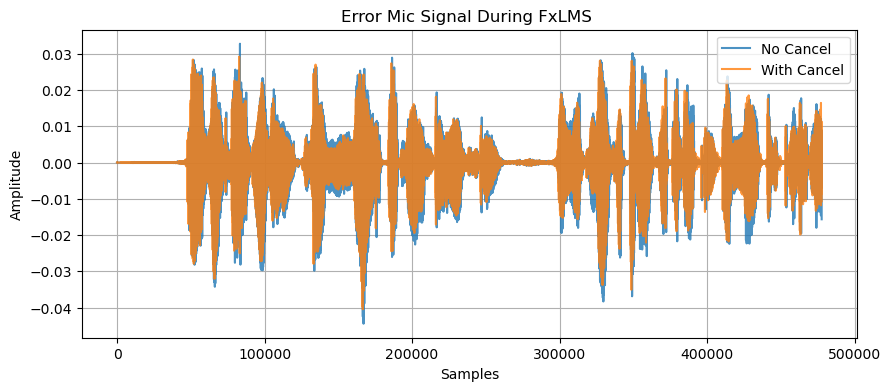

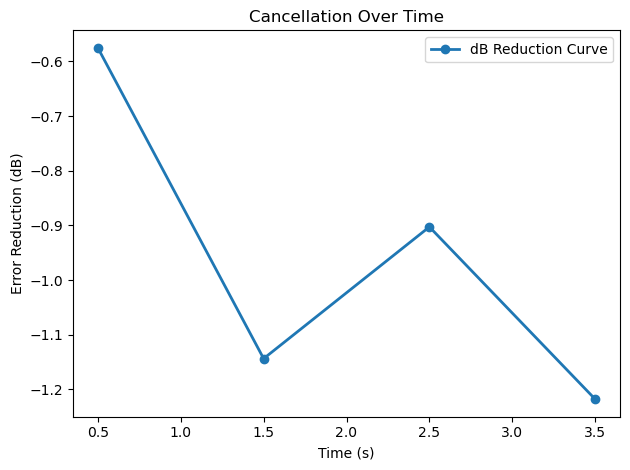

In [12]:
sharc.reset()
sharc.cancel(
    1,
    adapt=True,
    log_wnorm=False,
    mu=1e-3,
    cancel_gain=.15,
    leak=1e-7,
    clean_feedback=True,
    lag=92,
)
sharc.plot_error_mic()
sharc.plot_loss_curve()

In [13]:
sharc.no_cancel(5)

Overall ANC / No ANC: -1.12 dB


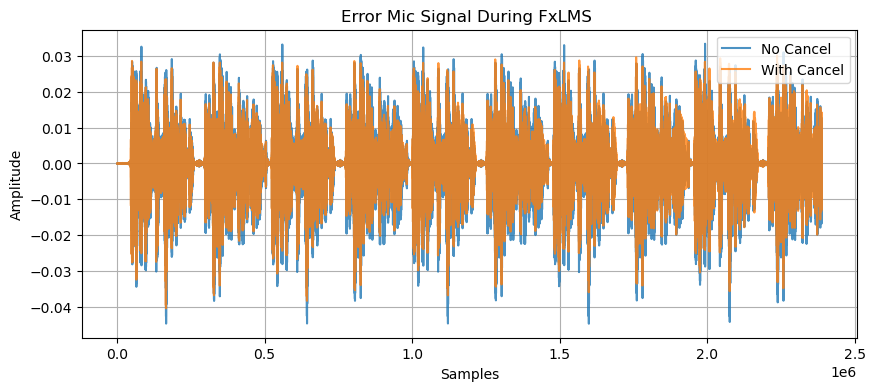

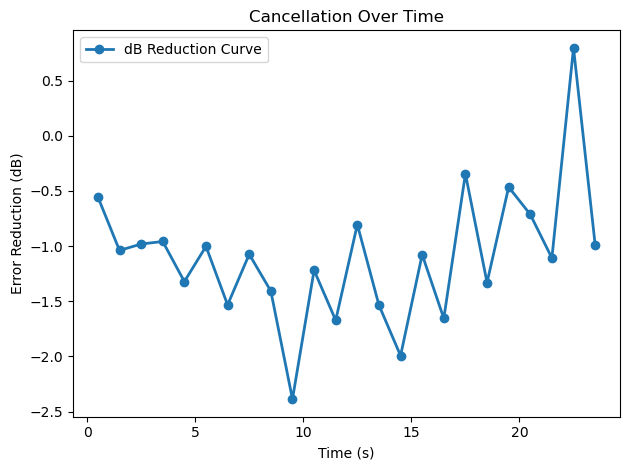

In [18]:
sharc.reset()
sharc.cancel(
    5,
    adapt=True,
    log_wnorm=False,
    mu=3e-4,
    cancel_gain=.11,
    leak=3e-7,
    clean_feedback=True,
    lag=92,
)
sharc.plot_error_mic()
sharc.plot_loss_curve()

Lag:  80
Overall ANC / No ANC: -0.77 dB

Lag:  82
Overall ANC / No ANC: -0.77 dB

Lag:  84
Overall ANC / No ANC: -0.68 dB

Lag:  86
Overall ANC / No ANC: -0.70 dB

Lag:  88
Overall ANC / No ANC: -0.82 dB

Lag:  90
Overall ANC / No ANC: -0.85 dB

Lag:  92
Overall ANC / No ANC: -0.85 dB

Lag:  94
Overall ANC / No ANC: -0.83 dB

Lag:  96
Overall ANC / No ANC: -0.91 dB

Lag:  98
Overall ANC / No ANC: -0.85 dB

Lag:  100
Overall ANC / No ANC: -0.86 dB

Lag:  102
Overall ANC / No ANC: -0.89 dB

Lag:  104
Overall ANC / No ANC: -0.89 dB

Lag:  106
Overall ANC / No ANC: -0.78 dB

Lag:  108
Overall ANC / No ANC: -0.90 dB

Lag:  110
Overall ANC / No ANC: -0.74 dB

Lag:  112
Overall ANC / No ANC: -0.78 dB

Lag:  114
Overall ANC / No ANC: -0.76 dB

Lag:  116
Overall ANC / No ANC: -0.80 dB

Lag:  118
Overall ANC / No ANC: -0.69 dB

Lag:  80
Overall ANC / No ANC: -0.84 dB

Lag:  82
Overall ANC / No ANC: -0.86 dB

Lag:  84
Overall ANC / No ANC: -0.88 dB

Lag:  86
Overall ANC / No ANC: -0.78 dB

Lag:  

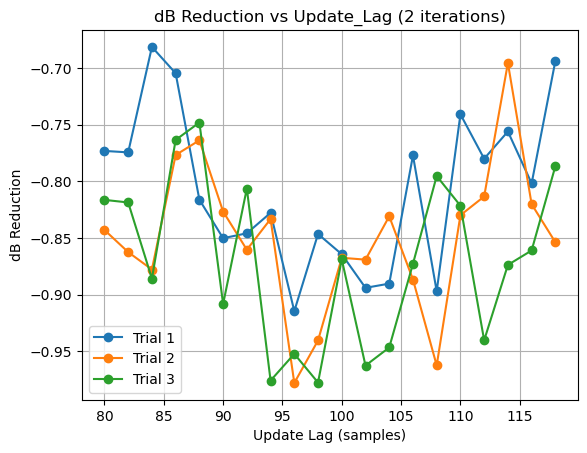

In [19]:
min_lag, max_lag, step, iters = 80, 120, 2, 2
lag_mu, lag_cancel_gain, lag_leak = 1e-3, 0.11, 3e-7

db_redux = lag_sweep(
    min_lag, max_lag, step, iters=iters,
    mu=lag_mu, cancel_gain=lag_cancel_gain, leak=lag_leak
)

In [20]:
sharc.no_cancel(10)
error_nc = sharc.no_cancels[10]
ref_nc = sharc.ref_log

Overall ANC / No ANC: -0.47 dB


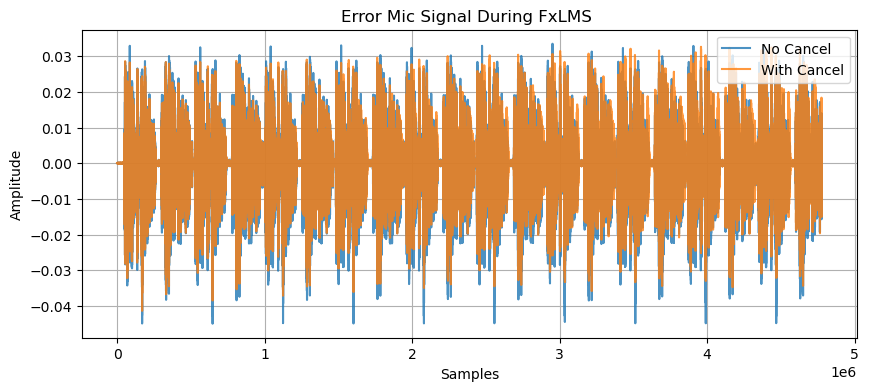

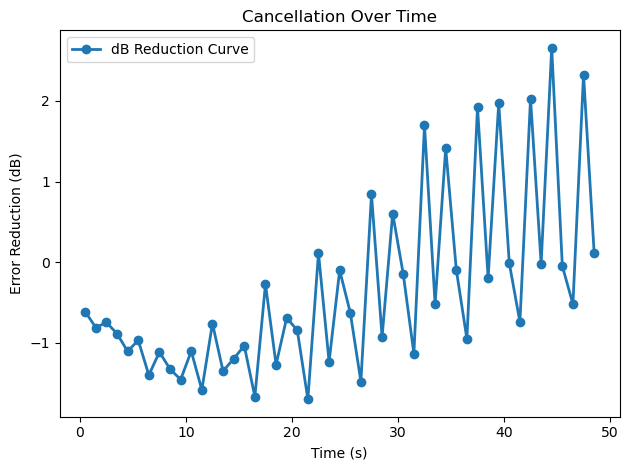

In [22]:
sharc.reset()
sharc.cancel(
    10,
    adapt=True,
    log_wnorm=True,
    mu=3e-4,
    cancel_gain=.11,
    leak=3e-7,
    clean_feedback=True,
    lag=96,
)
sharc.plot_error_mic()
sharc.plot_loss_curve()

In [ ]:
# sharc = Sharc(arthur_96, ad)


Using output: USB2.0-MIDI 2
Using input:  USB2.0-MIDI 1


In [23]:
learned_weights = sharc.get_weights()
true_norm = sharc.get_wnorm()

Weight transfer started: expecting 1024 values
Weight transfer complete: received 1024 values


In [24]:
irs = np.load('./data/current_irs.npz')
error_ir_raw = irs['error_ir']
ref_ir_raw = irs['ref_ir']
error_ir, ref_ir = align_irs_by_distance(error_ir_raw, ref_ir_raw, distance_cm=distance_cm, fs=fs, ir_len=ir_len)

np.savez(
    f'./data/separate_speaker/{filename}',
    error=sharc.error_log,
    ref=sharc.ref_log,
    error_nc=error_nc,
    ref_nc=ref_nc,
    source=sharc.source,

    error_ir=error_ir,
    ref_ir=ref_ir,
    error_ir_raw=error_ir_raw,
    ref_ir_raw=ref_ir_raw,

    learned_weights=learned_weights,
    w_norm_log = sharc.true_norm_log,
    w_norm = true_norm,

    lag_sweep=db_redux,
    lag_sweep_mu=lag_mu,
    lag_sqweep_cancel_gain=lag_cancel_gain,
    lag_sweep_leak=lag_leak,
    lags=list(range(min_lag, max_lag, step)),
    lag_iters=iters,

    n_repeats=10,
    fs=fs,
    ir_len=ir_len,
    panel_to_err_cm=panel_to_err_cm,
    speaker_to_err_cm=speaker_to_err_cm,

    mu=sharc.mu,
    leak=sharc.leak,
    eps=sharc.eps,
    lag=sharc.lag,
    cancel_gain=sharc.cancel_gain,
    ref_threshold=sharc.ref_threshold,
    mavg_tau_ms=sharc.mavg_tau_ms,
    update_sign=sharc.update_sign,
    clean_feedback=sharc.clean_feedback
)

___
___
___
# 10/7/2026

Overall ANC / No ANC: -1.49 dB


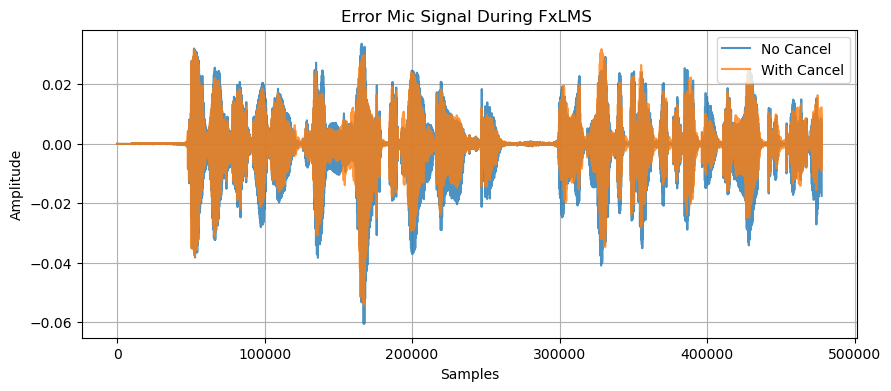

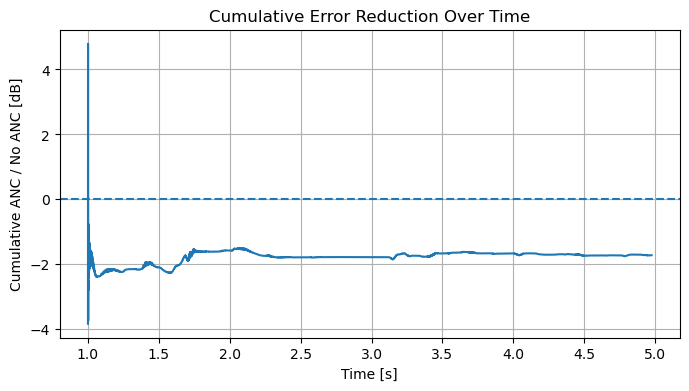

In [16]:
sharc.reset()
sharc.cancel(
    1,
    adapt=True,
    log_wnorm=False,
    mu=3e-3,
    cancel_gain=.15,
    leak=1e-7,
    clean_feedback=True,
    lag=94,
)
sharc.plot_error_mic()
sharc.plot_cumulative_error_reduction()

In [7]:
sharc.reset()
sharc.no_cancel(2)

In [17]:
lags = list(range(86, 112, 2))
db_redux = []
tmp_redux = []

for i in range(3):
    for lag in lags:
        print("Lag: ", lag)
        sharc.reset()
        db = sharc.cancel(
            2,
            adapt=True,
            log_wnorm=False,
            mu=1e-3,
            cancel_gain=0.15,
            leak=1e-7,
            clean_feedback=True,
            lag=lag,
        )
        tmp_redux.append(db)
        print()
    db_redux.append(tmp_redux)
    tmp_redux = []

Lag:  86
Overall ANC / No ANC: -0.80 dB

Lag:  88
Overall ANC / No ANC: -0.75 dB

Lag:  90
Overall ANC / No ANC: -0.79 dB

Lag:  92
Overall ANC / No ANC: -0.83 dB

Lag:  94
Overall ANC / No ANC: -0.85 dB

Lag:  96
Overall ANC / No ANC: -0.90 dB

Lag:  98
Overall ANC / No ANC: -0.89 dB

Lag:  100
Overall ANC / No ANC: -0.92 dB

Lag:  102
Overall ANC / No ANC: -0.90 dB

Lag:  104
Overall ANC / No ANC: -0.92 dB

Lag:  106
Overall ANC / No ANC: -0.90 dB

Lag:  108
Overall ANC / No ANC: -0.89 dB

Lag:  110
Overall ANC / No ANC: -0.89 dB

Lag:  86
Overall ANC / No ANC: -0.76 dB

Lag:  88
Overall ANC / No ANC: -0.77 dB

Lag:  90
Overall ANC / No ANC: -0.83 dB

Lag:  92
Overall ANC / No ANC: -0.86 dB

Lag:  94
Overall ANC / No ANC: -0.89 dB

Lag:  96
Overall ANC / No ANC: -0.92 dB

Lag:  98
Overall ANC / No ANC: -0.94 dB

Lag:  100
Overall ANC / No ANC: -0.96 dB

Lag:  102
Overall ANC / No ANC: -0.95 dB

Lag:  104
Overall ANC / No ANC: -0.93 dB

Lag:  106
Overall ANC / No ANC: -0.93 dB

Lag:  

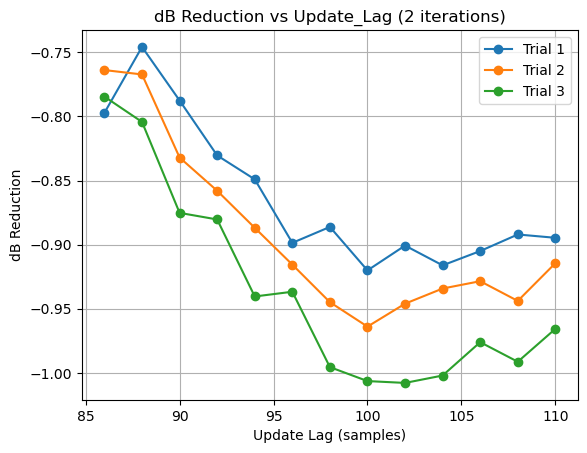

In [18]:
for i in range(len(db_redux)):
    plt.plot(lags, db_redux[i], marker='o', label=f"Trial {i+1}")

plt.title(f"dB Reduction vs Update_Lag (2 iterations)")
plt.xlabel("Update Lag (samples)")
plt.ylabel("dB Reduction")
plt.grid(True)
plt.legend()
plt.show()

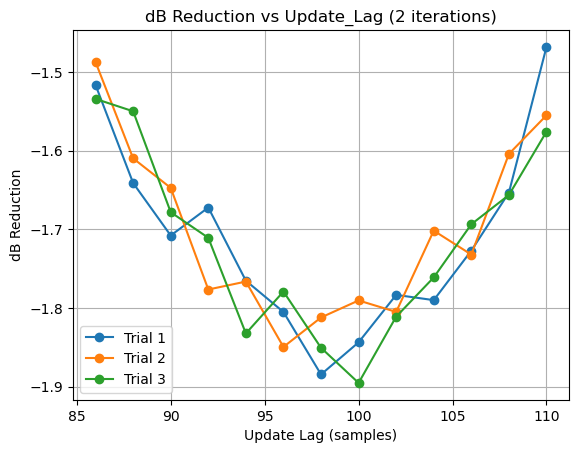

In [20]:
for i in range(len(db_redux)):
    plt.plot(lags, db_redux[i], marker='o', label=f"Trial {i+1}")

plt.title(f"dB Reduction vs Update_Lag (2 iterations)")
plt.xlabel("Update Lag (samples)")
plt.ylabel("dB Reduction")
plt.grid(True)
plt.legend()
plt.show()

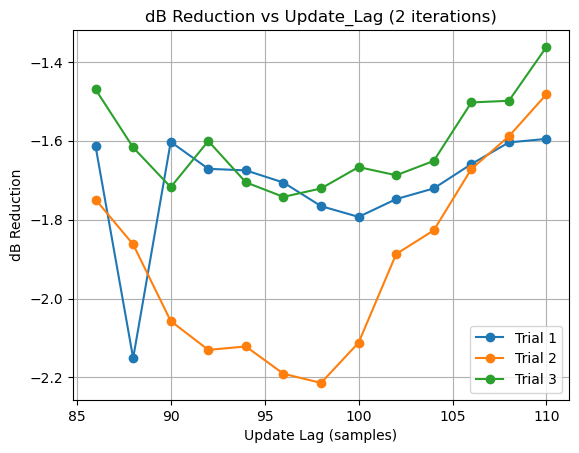

In [14]:
for i in range(len(db_redux)):
    plt.plot(lags, db_redux[i], marker='o', label=f"Trial {i+1}")

plt.title(f"dB Reduction vs Update_Lag (2 iterations)")
plt.xlabel("Update Lag (samples)")
plt.ylabel("dB Reduction")
plt.grid(True)
plt.legend()
plt.show()

Overall ANC / No ANC: -2.54 dB


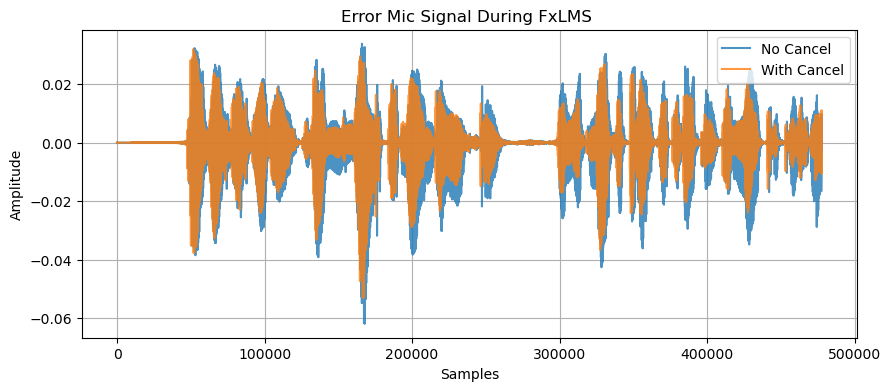

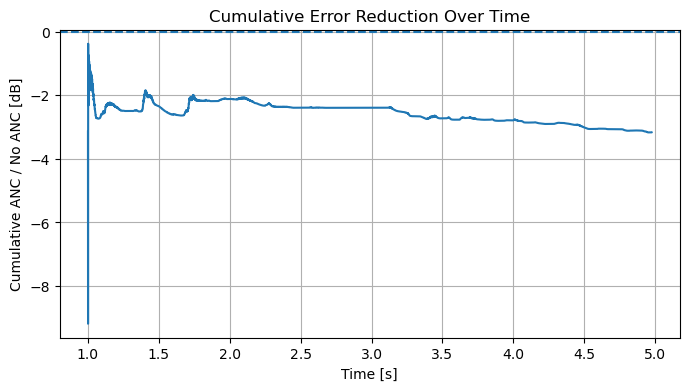

In [6]:
sharc.reset()
sharc.cancel(
    1,
    adapt=True,
    log_wnorm=False,
    mu=3e-3,
    cancel_gain=.15,
    leak=1e-7,
    clean_feedback=False,
    lag=92,
)
sharc.plot_error_mic()
sharc.plot_cumulative_error_reduction()

In [8]:
sharc.no_cancel(10)

Overall ANC / No ANC: -5.26 dB


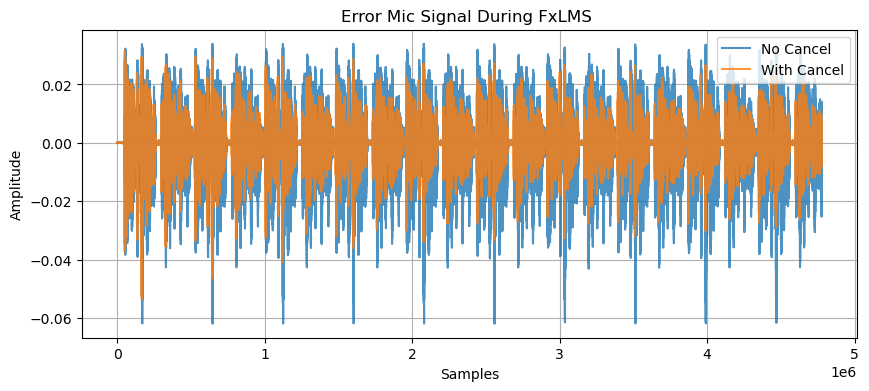

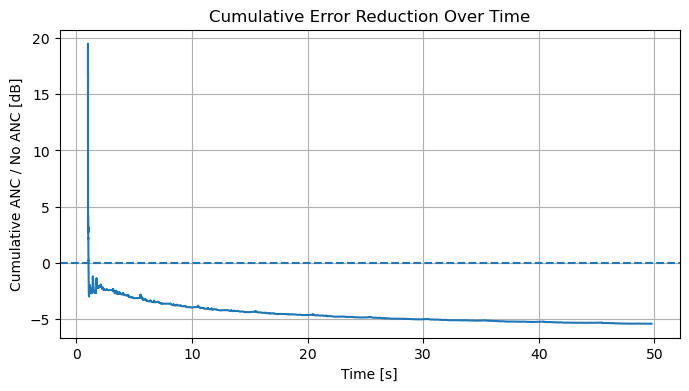

In [9]:
sharc.reset()
sharc.cancel(
    10,
    adapt=True,
    log_wnorm=False,
    mu=3e-3,
    cancel_gain=.15,
    leak=1e-7,
    clean_feedback=False,
    lag=92,
)
sharc.plot_error_mic()
sharc.plot_cumulative_error_reduction()

In [10]:
sharc.set_off(True)

In [13]:
sharc.reset()
sharc.no_cancel(2)

In [14]:
lags = list(range(86, 112, 2))
db_redux = []
tmp_redux = []

for i in range(3):
    for lag in lags:
        print("Lag: ", lag)
        sharc.reset()
        db = sharc.cancel(
            2,
            adapt=True,
            log_wnorm=False,
            mu=3e-3,
            cancel_gain=0.2,
            leak=5e-8,
            clean_feedback=True,
            lag=lag,
        )
        tmp_redux.append(db)
        print()
    db_redux.append(tmp_redux)
    tmp_redux = []

Lag:  86
Overall ANC / No ANC: -3.50 dB

Lag:  88
Overall ANC / No ANC: -3.63 dB

Lag:  90
Overall ANC / No ANC: -3.74 dB

Lag:  92
Overall ANC / No ANC: -3.83 dB

Lag:  94
Overall ANC / No ANC: -3.90 dB

Lag:  96
Overall ANC / No ANC: -3.93 dB

Lag:  98
Overall ANC / No ANC: -3.92 dB

Lag:  100
Overall ANC / No ANC: -3.90 dB

Lag:  102
Overall ANC / No ANC: -3.85 dB

Lag:  104
Overall ANC / No ANC: -3.75 dB

Lag:  106
Overall ANC / No ANC: -3.70 dB

Lag:  108
Overall ANC / No ANC: -3.61 dB

Lag:  110
Overall ANC / No ANC: -3.51 dB

Lag:  86
Overall ANC / No ANC: -3.49 dB

Lag:  88
Overall ANC / No ANC: -3.63 dB

Lag:  90
Overall ANC / No ANC: -3.75 dB

Lag:  92
Overall ANC / No ANC: -3.84 dB

Lag:  94
Overall ANC / No ANC: -3.89 dB

Lag:  96
Overall ANC / No ANC: -3.94 dB

Lag:  98
Overall ANC / No ANC: -3.93 dB

Lag:  100
Overall ANC / No ANC: -3.90 dB

Lag:  102
Overall ANC / No ANC: -3.84 dB

Lag:  104
Overall ANC / No ANC: -3.79 dB

Lag:  106
Overall ANC / No ANC: -3.68 dB

Lag:  

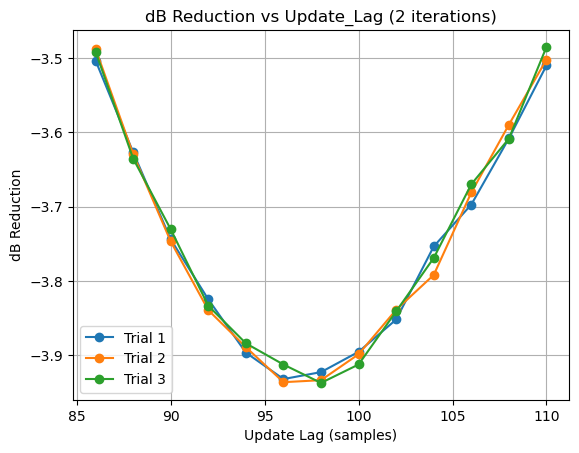

In [15]:
for i in range(len(db_redux)):
    plt.plot(lags, db_redux[i], marker='o', label=f"Trial {i+1}")

plt.title(f"dB Reduction vs Update_Lag (2 iterations)")
plt.xlabel("Update Lag (samples)")
plt.ylabel("dB Reduction")
plt.grid(True)
plt.legend()
plt.show()

Overall ANC / No ANC: -5.66 dB


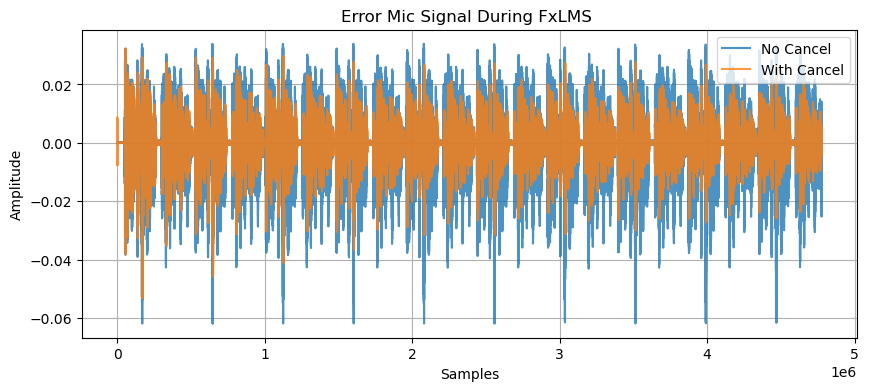

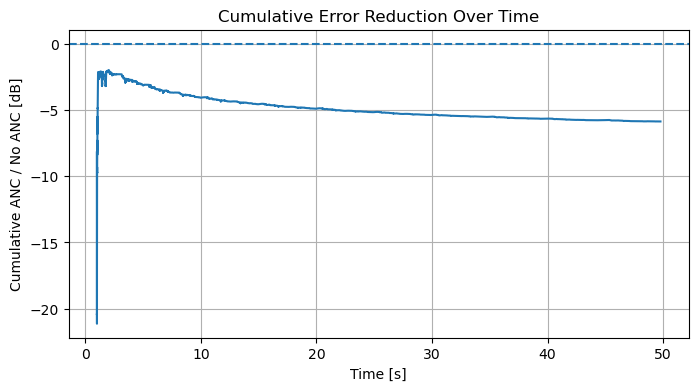

In [18]:
sharc.reset()
sharc.cancel(
    10,
    adapt=True,
    log_wnorm=False,
    mu=3e-3,
    cancel_gain=.15,
    leak=1e-7,
    clean_feedback=False,
    lag=97,
)
sharc.plot_error_mic()
sharc.plot_cumulative_error_reduction()

In [22]:
sharc.no_cancel(20)

In [23]:
error_nc = sharc.no_cancels[20]
ref_nc = sharc.ref_log

Overall ANC / No ANC: -5.87 dB


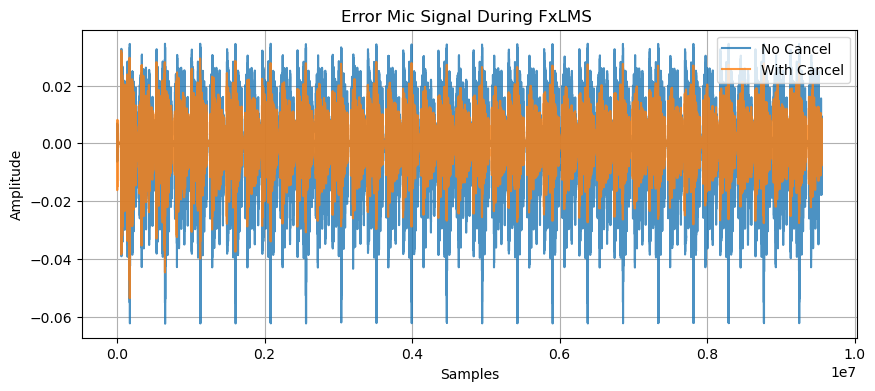

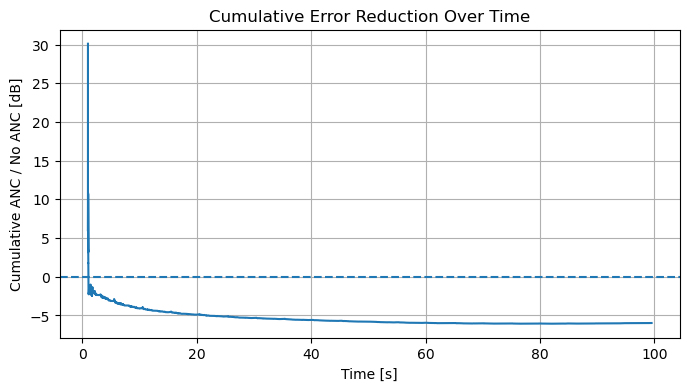

In [20]:
sharc.reset()
sharc.cancel(
    20,
    adapt=True,
    log_wnorm=False,
    mu=3e-3,
    cancel_gain=.15,
    leak=1e-7,
    clean_feedback=False,
    lag=97,
)
sharc.plot_error_mic()
sharc.plot_cumulative_error_reduction()

In [21]:
error = sharc.error_log
ref = sharc.ref_log

In [26]:
from src.measure_ir import *
irs = np.load('./data/current_irs.npz')
error_ir_raw = irs['error_ir']
ref_ir_raw = irs['ref_ir']
error_ir, ref_ir = align_irs_by_distance(error_ir_raw, ref_ir_raw, distance_cm=16, ir_len=256, fs=fs)

In [27]:
np.savez(
    './data/separate_speaker_results.npz',
    error=error,
    error_nc=error_nc,
    ref=ref,
    ref_nc=ref_nc,

    error_ir=error_ir,
    error_ir_raw = error_ir_raw,
    ref_ir=ref_ir,
    ref_ir_raw = ref_ir_raw,

    ir_len=256,
    speaker_to_err_cm=16,
    fs=fs,

    lag=97,
    mu=3e-3,
    cancel_gain=.15,
    leak=1e-7,
    clean_feedback=False,
)

___
___
___
# 10/6/2026

In [9]:
sharc.no_cancel(1)

Overall ANC / No ANC: -2.89 dB


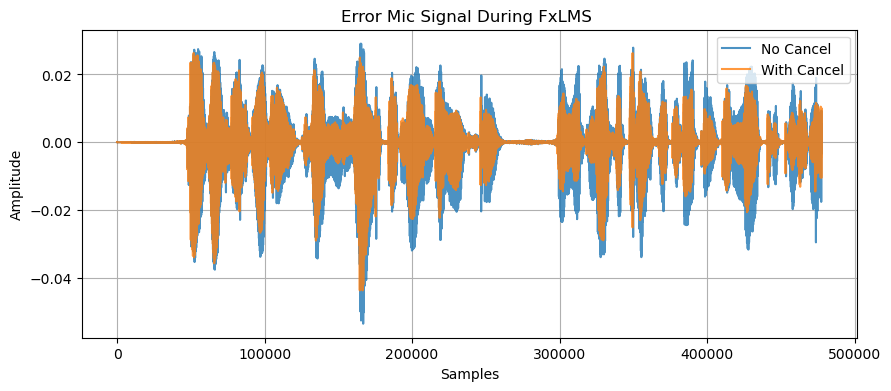

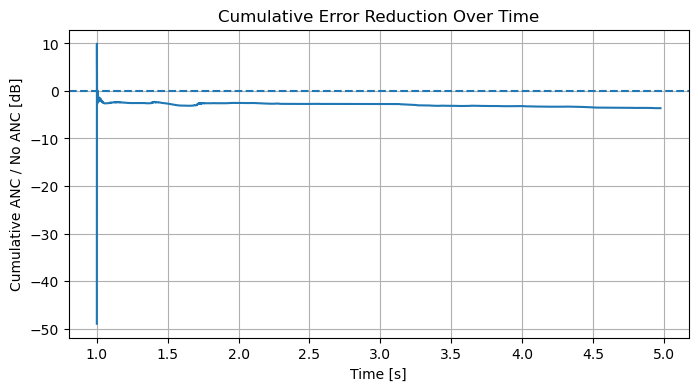

In [10]:
sharc.reset()
sharc.cancel(
    1,
    adapt=True,
    log_wnorm=False,
    mu=3e-3,
    cancel_gain=.15,
    leak=1e-7,
    clean_feedback=False,
    lag=92,
)
sharc.plot_error_mic()
sharc.plot_cumulative_error_reduction()

In [11]:
sharc.no_cancel(5)

Overall ANC / No ANC: -5.21 dB


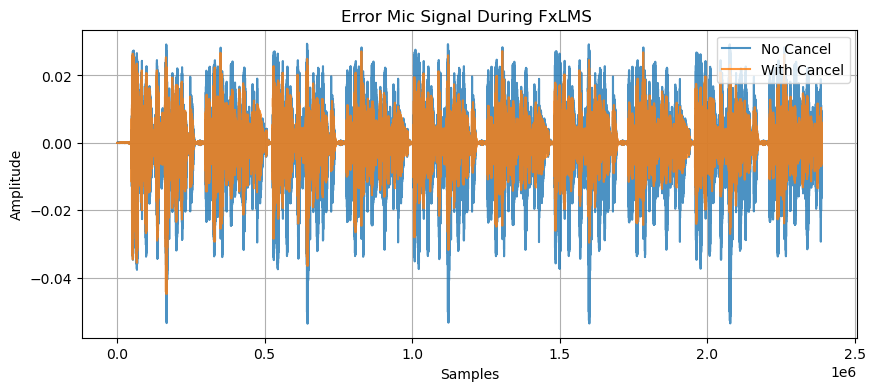

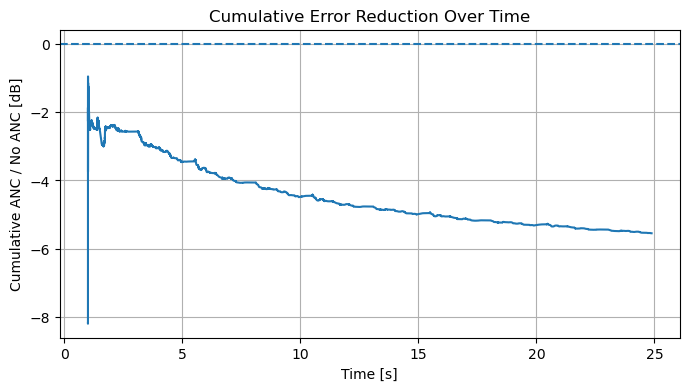

In [12]:
sharc.reset()
sharc.cancel(
    5,
    adapt=True,
    log_wnorm=False,
    mu=3e-3,
    cancel_gain=.15,
    leak=1e-7,
    clean_feedback=False,
    lag=92,
)
sharc.plot_error_mic()
sharc.plot_cumulative_error_reduction()

In [13]:
sharc.no_cancel(10)

Overall ANC / No ANC: -5.54 dB


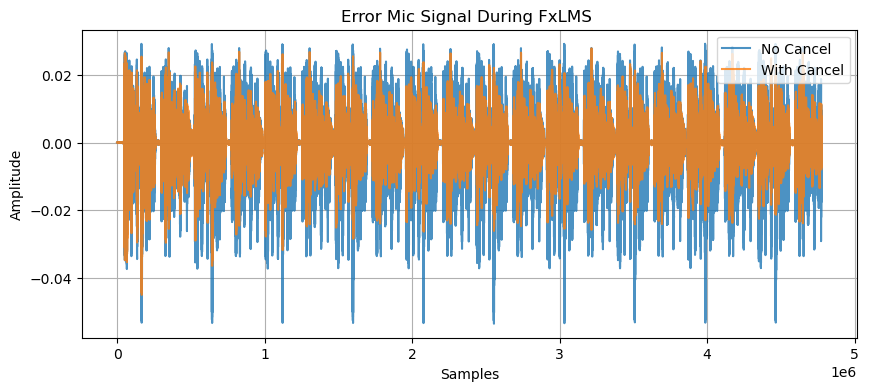

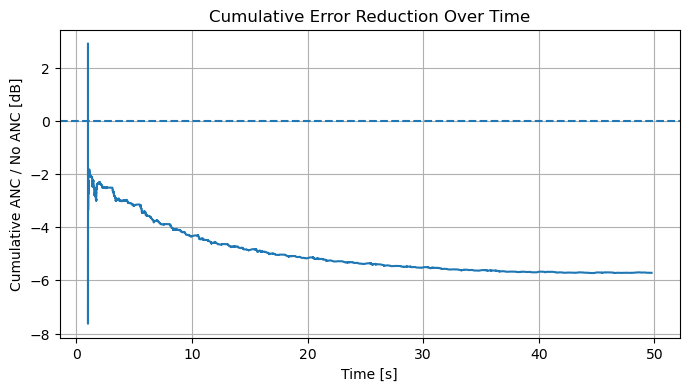

In [14]:
sharc.reset()
sharc.cancel(
    10,
    adapt=True,
    log_wnorm=False,
    mu=3e-3,
    cancel_gain=.15,
    leak=1e-7,
    clean_feedback=False,
    lag=92,
)
sharc.plot_error_mic()
sharc.plot_cumulative_error_reduction()

In [15]:
sharc.no_cancel(2)

In [16]:
lags = list(range(70, 122, 2))
db_redux = []

for lag in lags:
    print("Lag: ", lag)
    sharc.reset()
    db = sharc.cancel(
        2,
        adapt=True,
        log_wnorm=False,
        mu=1e-3,
        cancel_gain=0.15,
        leak=1e-7,
        clean_feedback=True,
        lag=lag,
    )
    db_redux.append(db)
    print()

Lag:  70
Overall ANC / No ANC: -1.99 dB

Lag:  72
Overall ANC / No ANC: -1.98 dB

Lag:  74
Overall ANC / No ANC: -2.06 dB

Lag:  76
Overall ANC / No ANC: -2.11 dB

Lag:  78
Overall ANC / No ANC: -2.18 dB

Lag:  80
Overall ANC / No ANC: -2.24 dB

Lag:  82
Overall ANC / No ANC: -2.30 dB

Lag:  84
Overall ANC / No ANC: -2.36 dB

Lag:  86
Overall ANC / No ANC: -2.41 dB

Lag:  88
Overall ANC / No ANC: -2.44 dB

Lag:  90
Overall ANC / No ANC: -2.48 dB

Lag:  92
Overall ANC / No ANC: -2.51 dB

Lag:  94
Overall ANC / No ANC: -2.54 dB

Lag:  96
Overall ANC / No ANC: -2.55 dB

Lag:  98
Overall ANC / No ANC: -2.55 dB

Lag:  100
Overall ANC / No ANC: -2.56 dB

Lag:  102
Overall ANC / No ANC: -2.57 dB

Lag:  104
Overall ANC / No ANC: -2.55 dB

Lag:  106
Overall ANC / No ANC: -2.54 dB

Lag:  108
Overall ANC / No ANC: -2.52 dB

Lag:  110
Overall ANC / No ANC: -2.51 dB

Lag:  112
Overall ANC / No ANC: -2.46 dB

Lag:  114
Overall ANC / No ANC: -2.42 dB

Lag:  116
Overall ANC / No ANC: -2.39 dB

Lag:  1

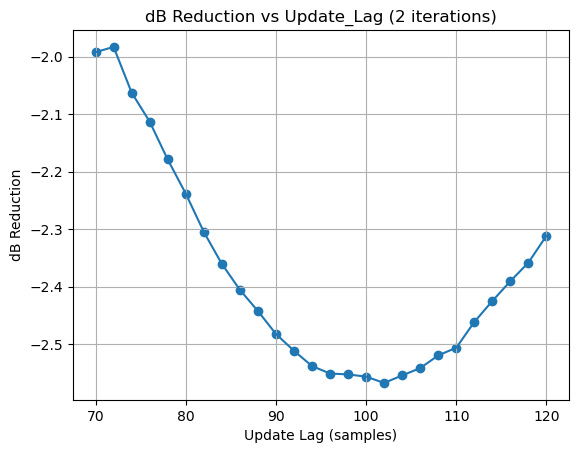

In [17]:
plt.plot(lags, db_redux)
plt.scatter(lags, db_redux)

plt.title(f"dB Reduction vs Update_Lag (2 iterations)")
plt.xlabel("Update Lag (samples)")
plt.ylabel("dB Reduction")
plt.grid(True)
plt.show()

In [18]:
lags2 = list(range(88, 114, 2))
db_redux2 = []

for lag in lags2:
    print("Lag: ", lag)
    sharc.reset()
    db = sharc.cancel(
        2,
        adapt=True,
        log_wnorm=False,
        mu=1e-3,
        cancel_gain=0.15,
        leak=1e-7,
        clean_feedback=True,
        lag=lag,
    )
    db_redux2.append(db)
    print()

Lag:  88
Overall ANC / No ANC: -2.39 dB

Lag:  90
Overall ANC / No ANC: -2.45 dB

Lag:  92
Overall ANC / No ANC: -2.49 dB

Lag:  94
Overall ANC / No ANC: -2.53 dB

Lag:  96
Overall ANC / No ANC: -2.55 dB

Lag:  98
Overall ANC / No ANC: -2.57 dB

Lag:  100
Overall ANC / No ANC: -2.57 dB

Lag:  102
Overall ANC / No ANC: -2.57 dB

Lag:  104
Overall ANC / No ANC: -2.55 dB

Lag:  106
Overall ANC / No ANC: -2.55 dB

Lag:  108
Overall ANC / No ANC: -2.53 dB

Lag:  110
Overall ANC / No ANC: -2.50 dB

Lag:  112
Overall ANC / No ANC: -2.48 dB



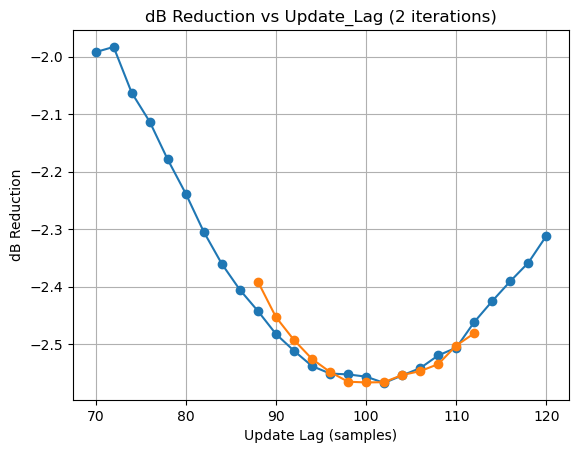

In [19]:
plt.plot(lags, db_redux, marker='o')
plt.plot(lags2, db_redux2, marker='o')

plt.title(f"dB Reduction vs Update_Lag (2 iterations)")
plt.xlabel("Update Lag (samples)")
plt.ylabel("dB Reduction")
plt.grid(True)
plt.show()

In [20]:
lags3 = list(range(88, 114, 2))
db_redux3 = []

for lag in lags3:
    print("Lag: ", lag)
    sharc.reset()
    db = sharc.cancel(
        2,
        adapt=True,
        log_wnorm=False,
        mu=1e-3,
        cancel_gain=0.15,
        leak=1e-7,
        clean_feedback=True,
        lag=lag,
    )
    db_redux3.append(db)
    print()

Lag:  88
Overall ANC / No ANC: -2.40 dB

Lag:  90
Overall ANC / No ANC: -2.45 dB

Lag:  92
Overall ANC / No ANC: -2.49 dB

Lag:  94
Overall ANC / No ANC: -2.53 dB

Lag:  96
Overall ANC / No ANC: -2.55 dB

Lag:  98
Overall ANC / No ANC: -2.57 dB

Lag:  100
Overall ANC / No ANC: -2.57 dB

Lag:  102
Overall ANC / No ANC: -2.58 dB

Lag:  104
Overall ANC / No ANC: -2.57 dB

Lag:  106
Overall ANC / No ANC: -2.55 dB

Lag:  108
Overall ANC / No ANC: -2.53 dB

Lag:  110
Overall ANC / No ANC: -2.50 dB

Lag:  112
Overall ANC / No ANC: -2.48 dB



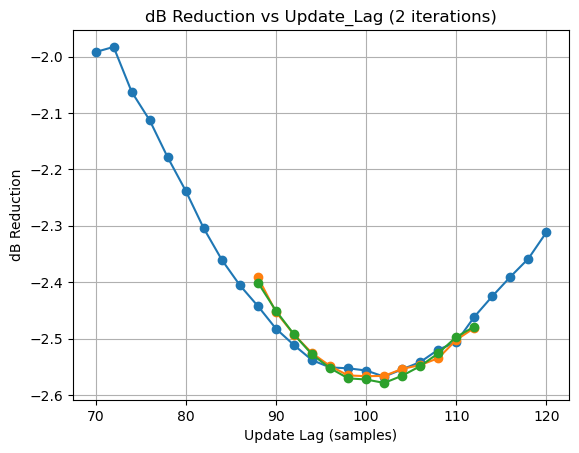

In [21]:
plt.plot(lags, db_redux, marker='o')
plt.plot(lags2, db_redux2, marker='o')
plt.plot(lags3, db_redux3, marker='o')


plt.title(f"dB Reduction vs Update_Lag (2 iterations)")
plt.xlabel("Update Lag (samples)")
plt.ylabel("dB Reduction")
plt.grid(True)
plt.show()

Overall ANC / No ANC: -5.75 dB


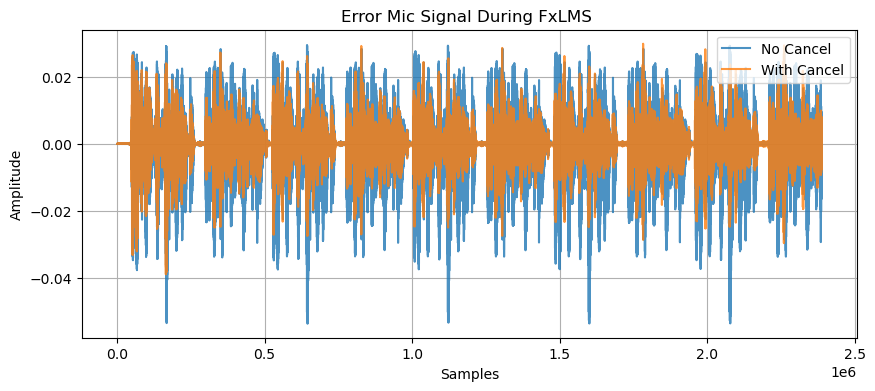

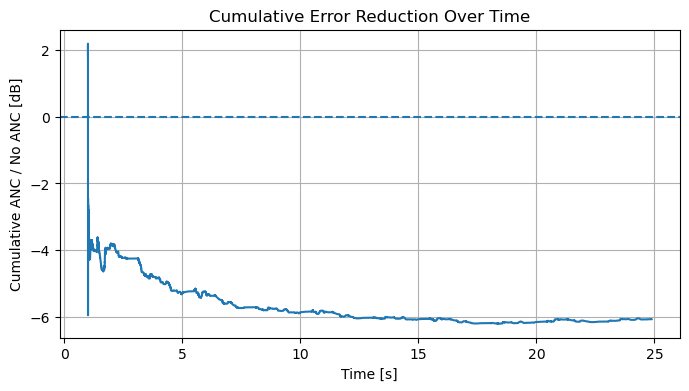

In [28]:
sharc.reset()
sharc.cancel(
    5,
    adapt=True,
    log_wnorm=False,
    mu=5e-3,
    cancel_gain=.25,
    leak=5e-8,
    clean_feedback=True,
    lag=102,
)
sharc.plot_error_mic()
sharc.plot_cumulative_error_reduction()